# A9 — Learning the Depth Information for Kinect Skeleton Avatars with PyTorch and MLflow

This notebook evaluates deep learning models for predicting Kinect depth values (`z`) from 2D joint coordinates (`x`, `y`).

Tested model families:
- Dense
- Conv1D

The task is formulated as a sequence-to-sequence regression problem:
- **Input per frame:** 13 joints × 2 coordinates = 26 features
- **Target per frame:** 13 joints × z coordinate = 13 values

This notebook follows the Lab 9 instructions by:
- going through the Deep Learning steps
- varying hyperparameters
- using cross-validation
- suggesting the optimal setup
- documenting dead ends
- reporting accuracy in a user-understandable metric
- saving the champion model for reuse
- logging experiments with MLflow

## Imports and shared configuration

In [24]:
from pathlib import Path
import os
import random
import warnings
import copy
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv


warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# Shared experiment settings
SEQ_LEN = 20
STRIDE = 1
N_SPLITS = 5
VALIDATION_SPLIT = 0.10

BATCH_SIZE = 32
EPOCHS = 100
PATIENCE = 10
LEARNING_RATE = 1e-3

LOSS_NAME = "mse"
DEFAULT_OPTIMIZER = "adam"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Keep the same path style as your previous notebook
DATA_DIR = Path("../../data/raw/kinect_good_preprocessed")

# Reporting / artifact paths
output_dir = Path("reporting/results")
output_dir.mkdir(parents=True, exist_ok=True)

artifact_dir = Path("reporting/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

JOINTS = [
    "head",
    "left_shoulder",
    "left_elbow",
    "right_shoulder",
    "right_elbow",
    "left_hand",
    "right_hand",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_foot",
    "right_foot",
]

INPUT_FEATURES = [f"{j}_{axis}" for j in JOINTS for axis in ["x", "y"]]
TARGET_FEATURES = [f"{j}_z" for j in JOINTS]

FRAME_COL_CANDIDATES = ["FrameNo", "frame", "frame_no", "Frame", "frameno"]
SEQUENCE_COL_CANDIDATES = ["sequence_id", "SequenceId", "movement_id", "MovementId", "id", "ID"]

# Set this based on your raw z-values
TARGET_UNIT = "meters"

def to_cm(value):
    if TARGET_UNIT == "meters":
        return value * 100.0
    return value

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)
print("Input features:", len(INPUT_FEATURES))
print("Target features:", len(TARGET_FEATURES))

PyTorch version: 2.11.0+cpu
Device: cpu
Input features: 26
Target features: 13


## MLFlow setup

In [25]:
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A9_dense_conv1d_depth_regression"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A9_dense_conv1d_depth_regression


## Helper functions

In [26]:
def read_table_file(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".tsv":
        return pd.read_csv(path, sep="\t")
    if suffix == ".txt":
        try:
            df = pd.read_csv(path)
            if df.shape[1] > 1:
                return df
        except Exception:
            pass
        return pd.read_csv(path, delim_whitespace=True)
    if suffix in [".xlsx", ".xls"]:
        return pd.read_excel(path)
    if suffix == ".parquet":
        return pd.read_parquet(path)
    raise ValueError(f"Unsupported file type: {path}")


def find_frame_col(df: pd.DataFrame):
    lower_map = {c.lower(): c for c in df.columns}
    for col in FRAME_COL_CANDIDATES:
        if col.lower() in lower_map:
            return lower_map[col.lower()]
    return None


def find_sequence_col(df: pd.DataFrame):
    lower_map = {c.lower(): c for c in df.columns}
    for col in SEQUENCE_COL_CANDIDATES:
        if col.lower() in lower_map:
            return lower_map[col.lower()]
    return None


def standardize_joint_column_names(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    rename_map = {}
    for col in df.columns:
        normalized = col.strip().lower().replace(" ", "_").replace("-", "_")
        rename_map[col] = normalized
    return df.rename(columns=rename_map)

## Load Kinect movement data

In [27]:
def load_kinect_data(data_dir: Path) -> pd.DataFrame:
    if not data_dir.exists():
        raise FileNotFoundError(
            f"DATA_DIR does not exist: {data_dir}\n"
            "Update DATA_DIR in the config cell to your raw Kinect folder."
        )

    files = []
    for pattern in ["*.csv", "*.tsv", "*.txt", "*.xlsx", "*.xls", "*.parquet"]:
        files.extend(sorted(data_dir.glob(pattern)))

    if not files:
        raise FileNotFoundError(
            f"No supported data files found in {data_dir}.\n"
            "Expected csv, tsv, txt, xlsx, xls, or parquet."
        )

    dfs = []
    for file_path in files:
        df = read_table_file(file_path)
        df = standardize_joint_column_names(df)

        seq_col = find_sequence_col(df)
        if seq_col is None:
            df["sequence_id"] = file_path.stem
        elif seq_col != "sequence_id":
            df = df.rename(columns={seq_col: "sequence_id"})

        frame_col = find_frame_col(df)
        if frame_col is None:
            df["frameno"] = np.arange(len(df))
        elif frame_col != "frameno":
            df = df.rename(columns={frame_col: "frameno"})

        dfs.append(df)

    full_df = pd.concat(dfs, ignore_index=True)
    full_df = full_df.sort_values(["sequence_id", "frameno"]).reset_index(drop=True)
    return full_df

df = load_kinect_data(DATA_DIR)

print("Shape:", df.shape)
print("Columns:", len(df.columns))
display(df.head())

missing_inputs = [c for c in INPUT_FEATURES if c not in df.columns]
missing_targets = [c for c in TARGET_FEATURES if c not in df.columns]

print("Missing input columns:", missing_inputs)
print("Missing target columns:", missing_targets)

assert not missing_inputs, "Missing input columns."
assert not missing_targets, "Missing target columns."

Shape: (24005, 41)
Columns: 41


,frameno,head_x,head_y,head_z,left_shoulder_x,left_shoulder_y,left_shoulder_z,left_elbow_x,left_elbow_y,left_elbow_z,...,right_knee_x,right_knee_y,right_knee_z,left_foot_x,left_foot_y,left_foot_z,right_foot_x,right_foot_y,right_foot_z,sequence_id
0,3,-0.016480,0.77960,0.070646,-0.16221,0.58030,0.047752,-0.23056,0.84519,-0.033909,...,0.13624,-0.51948,0.003528,-0.13975,-0.86193,-0.025068,0.15162,-0.91701,-0.005627,A100_kinect
1,4,-0.016990,0.77937,0.069989,-0.16242,0.58031,0.047168,-0.23050,0.84547,-0.034061,...,0.13663,-0.51921,0.003291,-0.13982,-0.86208,-0.024980,0.15001,-0.91352,-0.001491,A100_kinect
2,5,-0.017345,0.77928,0.069703,-0.16258,0.58039,0.046964,-0.23044,0.84564,-0.034175,...,0.13633,-0.51957,0.003223,-0.13937,-0.86233,-0.024777,0.14981,-0.91385,-0.001252,A100_kinect
3,6,-0.017602,0.77935,0.069520,-0.16276,0.58035,0.046524,-0.23037,0.84598,-0.034318,...,0.13653,-0.51892,0.002961,-0.13907,-0.86225,-0.024431,0.15711,-0.92048,-0.014920,A100_kinect
4,7,-0.017559,0.77938,0.069530,-0.16279,0.58030,0.046288,-0.22906,0.85070,-0.036518,...,0.13662,-0.51940,0.002998,-0.13917,-0.86364,-0.025274,0.15212,-0.91871,-0.004539,A100_kinect


Missing input columns: []
Missing target columns: []


## Build fixed-length sequences

In [28]:
def build_sequences(
    df: pd.DataFrame,
    input_cols,
    target_cols,
    seq_len: int = 20,
    stride: int = 1,
):
    X_list = []
    y_list = []
    seq_ids = []

    clean_df = df.dropna(subset=input_cols + target_cols).copy()

    for seq_id, group in clean_df.groupby("sequence_id"):
        group = group.sort_values("frameno").reset_index(drop=True)

        x_values = group[input_cols].to_numpy(dtype=np.float32)
        y_values = group[target_cols].to_numpy(dtype=np.float32)

        if len(group) < seq_len:
            continue

        for start in range(0, len(group) - seq_len + 1, stride):
            end = start + seq_len
            X_list.append(x_values[start:end])
            y_list.append(y_values[start:end])
            seq_ids.append(seq_id)

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.float32)
    seq_ids = np.array(seq_ids)

    return X, y, seq_ids

X, y, seq_ids = build_sequences(
    df=df,
    input_cols=INPUT_FEATURES,
    target_cols=TARGET_FEATURES,
    seq_len=SEQ_LEN,
    stride=STRIDE,
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("seq_ids shape:", seq_ids.shape)

X shape: (20604, 20, 26)
y shape: (20604, 20, 13)
seq_ids shape: (20604,)


## Inspect target scale

In [29]:
z_summary = df[TARGET_FEATURES].describe().T[["mean", "std", "min", "max"]]
display(z_summary)

print("TARGET_UNIT =", TARGET_UNIT)

,mean,std,min,max
head_z,-0.041466,0.096579,-0.37941,0.188800
left_shoulder_z,-0.037638,0.073275,-0.31771,0.154210
left_elbow_z,-0.147002,0.116080,-0.54195,0.128840
right_shoulder_z,-0.038818,0.078787,-0.33537,0.186630
right_elbow_z,-0.134302,0.123639,-0.56776,0.329820
left_hand_z,-0.239894,0.161802,-0.79979,0.125770
right_hand_z,-0.220100,0.164971,-0.81429,0.464960
left_hip_z,0.046929,0.086418,-0.30135,0.364500
right_hip_z,0.046611,0.088141,-0.32356,0.384430
left_knee_z,-0.136890,0.097322,-0.59866,0.110160


TARGET_UNIT = meters


## Dataset and scaling helpers

In [30]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]
    
def fit_scaler_on_training_sequences(X_train):
    scaler = StandardScaler()
    X_train_2d = X_train.reshape(-1, X_train.shape[-1])
    scaler.fit(X_train_2d)
    return scaler


def transform_sequences(X_data, scaler):
    X_2d = X_data.reshape(-1, X_data.shape[-1])
    X_scaled = scaler.transform(X_2d).reshape(X_data.shape).astype(np.float32)
    return X_scaled

## Define Deep Learning models

In [31]:
class DenseDepthRegressor(nn.Module):
    def __init__(self, seq_len, n_features, n_targets, hidden_units=(256, 128), dropout_rate=0.0):
        super().__init__()
        input_dim = seq_len * n_features
        output_dim = seq_len * n_targets

        layers_list = []
        prev_dim = input_dim

        for units in hidden_units:
            layers_list.append(nn.Linear(prev_dim, units))
            layers_list.append(nn.ReLU())
            if dropout_rate > 0:
                layers_list.append(nn.Dropout(dropout_rate))
            prev_dim = units

        layers_list.append(nn.Linear(prev_dim, output_dim))
        self.network = nn.Sequential(*layers_list)

        self.seq_len = seq_len
        self.n_targets = n_targets

    def forward(self, x):
        batch_size = x.shape[0]
        x = x.reshape(batch_size, -1)
        out = self.network(x)
        out = out.reshape(batch_size, self.seq_len, self.n_targets)
        return out
    
class Conv1DDepthRegressor(nn.Module):
    def __init__(self, n_features, n_targets, filters=(64, 128), kernel_size=3, dropout_rate=0.0):
        super().__init__()

        conv_layers = []
        in_channels = n_features

        for f in filters:
            conv_layers.append(nn.Conv1d(in_channels, f, kernel_size=kernel_size, padding="same"))
            conv_layers.append(nn.ReLU())
            if dropout_rate > 0:
                conv_layers.append(nn.Dropout(dropout_rate))
            in_channels = f

        self.feature_extractor = nn.Sequential(*conv_layers)
        self.output_layer = nn.Conv1d(in_channels, n_targets, kernel_size=1)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.feature_extractor(x)
        x = self.output_layer(x)
        x = x.transpose(1, 2)
        return x
    

def build_model(model_family, config):
    if model_family == "Dense":
        return DenseDepthRegressor(
            seq_len=SEQ_LEN,
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            hidden_units=config["hidden_units"],
            dropout_rate=config.get("dropout_rate", 0.0),
        )
    elif model_family == "Conv1D":
        return Conv1DDepthRegressor(
            n_features=len(INPUT_FEATURES),
            n_targets=len(TARGET_FEATURES),
            filters=config["filters"],
            kernel_size=config["kernel_size"],
            dropout_rate=config.get("dropout_rate", 0.0),
        )
    else:
        raise ValueError(f"Unknown model_family: {model_family}")

## Training and evaluation helpers

In [32]:
def get_optimizer(model, optimizer_name="adam", lr=LEARNING_RATE):
    if optimizer_name.lower() == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr)
    elif optimizer_name.lower() == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")
    
def evaluate_loss(model, data_loader, criterion):
    model.eval()
    total_loss = 0.0
    n_samples = 0

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            preds = model(X_batch)
            loss = criterion(preds, y_batch)

            batch_size = X_batch.size(0)
            total_loss += loss.item() * batch_size
            n_samples += batch_size

    return total_loss / max(n_samples, 1)


def predict_model(model, data_loader):
    model.eval()
    preds_all = []
    targets_all = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(DEVICE)
            preds = model(X_batch).cpu().numpy()
            preds_all.append(preds)
            targets_all.append(y_batch.numpy())

    y_pred = np.concatenate(preds_all, axis=0)
    y_true = np.concatenate(targets_all, axis=0)
    return y_true, y_pred


def per_joint_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred), axis=(0, 1))

def train_model(
    model,
    train_loader,
    val_loader,
    optimizer_name="adam",
    lr=LEARNING_RATE,
    epochs=EPOCHS,
    patience=PATIENCE,
):
    model = model.to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = get_optimizer(model, optimizer_name=optimizer_name, lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_mae": [],
        "val_mae": [],
    }

    best_model_state = copy.deepcopy(model.state_dict())
    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0
        total_train_mae = 0.0
        n_train = 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()
            preds = model(X_batch)
            loss = criterion(preds, y_batch)
            loss.backward()
            optimizer.step()

            batch_size = X_batch.size(0)
            total_train_loss += loss.item() * batch_size
            total_train_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
            n_train += batch_size

        train_loss = total_train_loss / max(n_train, 1)
        train_mae = total_train_mae / max(n_train, 1)

        val_loss = evaluate_loss(model, val_loader, criterion)

        model.eval()
        total_val_mae = 0.0
        n_val = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)
                preds = model(X_batch)
                batch_size = X_batch.size(0)
                total_val_mae += torch.mean(torch.abs(preds - y_batch)).item() * batch_size
                n_val += batch_size
        val_mae = total_val_mae / max(n_val, 1)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    model.load_state_dict(best_model_state)
    return model, history, best_val_loss, best_epoch

## Experiment configurations

In [33]:
experiment_configs = [
    {
        "model_family": "Dense",
        "model_variant": "Dense_256_128",
        "hidden_units": (256, 128),
        "dropout_rate": 0.0,
    },
    {
        "model_family": "Dense",
        "model_variant": "Dense_512_256_128_dropout",
        "hidden_units": (512, 256, 128),
        "dropout_rate": 0.2,
    },
    {
        "model_family": "Conv1D",
        "model_variant": "Conv1D_64_128_k3",
        "filters": (64, 128),
        "kernel_size": 3,
        "dropout_rate": 0.0,
    },
    {
        "model_family": "Conv1D",
        "model_variant": "Conv1D_64_128_128_k5_dropout",
        "filters": (64, 128, 128),
        "kernel_size": 5,
        "dropout_rate": 0.2,
    },
]

experiment_configs

[{'model_family': 'Dense',
  'model_variant': 'Dense_256_128',
  'hidden_units': (256, 128),
  'dropout_rate': 0.0},
 {'model_family': 'Dense',
  'model_variant': 'Dense_512_256_128_dropout',
  'hidden_units': (512, 256, 128),
  'dropout_rate': 0.2},
 {'model_family': 'Conv1D',
  'model_variant': 'Conv1D_64_128_k3',
  'filters': (64, 128),
  'kernel_size': 3,
  'dropout_rate': 0.0},
 {'model_family': 'Conv1D',
  'model_variant': 'Conv1D_64_128_128_k5_dropout',
  'filters': (64, 128, 128),
  'kernel_size': 5,
  'dropout_rate': 0.2}]

## Cross-validation with MLflow logging

In [34]:
def run_cv_experiment(X, y, seq_ids, config):
    gkf = GroupKFold(n_splits=N_SPLITS)

    fold_results = []
    fold_histories = []

    with mlflow.start_run(run_name=config["model_variant"], nested=False):
        mlflow.log_param("model_family", config["model_family"])
        mlflow.log_param("model_variant", config["model_variant"])
        mlflow.log_param("sequence_length", SEQ_LEN)
        mlflow.log_param("stride", STRIDE)
        mlflow.log_param("n_splits", N_SPLITS)
        mlflow.log_param("batch_size", BATCH_SIZE)
        mlflow.log_param("epochs", EPOCHS)
        mlflow.log_param("patience", PATIENCE)
        mlflow.log_param("learning_rate", LEARNING_RATE)
        mlflow.log_param("optimizer", DEFAULT_OPTIMIZER)
        mlflow.log_param("loss", LOSS_NAME)
        mlflow.log_param("target_unit", TARGET_UNIT)

        for key, value in config.items():
            if key not in ["model_family", "model_variant"]:
                mlflow.log_param(key, str(value))

        for fold_idx, (train_val_idx, test_idx) in enumerate(gkf.split(X, y, groups=seq_ids), start=1):
            X_train_val = X[train_val_idx]
            y_train_val = y[train_val_idx]
            seq_train_val = seq_ids[train_val_idx]

            X_test = X[test_idx]
            y_test = y[test_idx]

            unique_train_sequences = np.unique(seq_train_val)
            train_seq_ids, val_seq_ids = train_test_split(
                unique_train_sequences,
                test_size=VALIDATION_SPLIT,
                random_state=RANDOM_SEED + fold_idx,
            )

            train_mask = np.isin(seq_train_val, train_seq_ids)
            val_mask = np.isin(seq_train_val, val_seq_ids)

            X_train = X_train_val[train_mask]
            y_train = y_train_val[train_mask]
            X_val = X_train_val[val_mask]
            y_val = y_train_val[val_mask]

            scaler = fit_scaler_on_training_sequences(X_train)
            X_train_scaled = transform_sequences(X_train, scaler)
            X_val_scaled = transform_sequences(X_val, scaler)
            X_test_scaled = transform_sequences(X_test, scaler)

            train_dataset = SequenceDataset(X_train_scaled, y_train)
            val_dataset = SequenceDataset(X_val_scaled, y_val)
            test_dataset = SequenceDataset(X_test_scaled, y_test)

            train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
            val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
            test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

            model = build_model(config["model_family"], config)

            trained_model, history, best_val_loss, best_epoch = train_model(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                optimizer_name=DEFAULT_OPTIMIZER,
                lr=LEARNING_RATE,
                epochs=EPOCHS,
                patience=PATIENCE,
            )

            y_true, y_pred = predict_model(trained_model, test_loader)

            test_mae = mean_absolute_error(
                y_true.reshape(-1, y_true.shape[-1]),
                y_pred.reshape(-1, y_pred.shape[-1]),
            )
            test_mae_cm = to_cm(test_mae)

            joint_errors = per_joint_mae(y_true, y_pred)
            joint_errors_cm = [to_cm(v) for v in joint_errors]

            mlflow.log_metric(f"fold_{fold_idx}_test_mae", float(test_mae))
            mlflow.log_metric(f"fold_{fold_idx}_test_mae_cm", float(test_mae_cm))
            mlflow.log_metric(f"fold_{fold_idx}_best_val_loss", float(best_val_loss))
            mlflow.log_metric(f"fold_{fold_idx}_best_epoch", int(best_epoch))

            fold_result = {
                "fold": fold_idx,
                "model_family": config["model_family"],
                "model_variant": config["model_variant"],
                "test_mae": float(test_mae),
                "test_mae_cm": float(test_mae_cm),
                "best_val_loss": float(best_val_loss),
                "best_epoch": int(best_epoch),
                "n_train_sequences": int(len(X_train)),
                "n_val_sequences": int(len(X_val)),
                "n_test_sequences": int(len(X_test)),
                "joint_mae_cm": joint_errors_cm,
            }

            fold_results.append(fold_result)
            fold_histories.append(history)

        fold_df = pd.DataFrame(fold_results)

        mlflow.log_metric("mean_test_mae", float(fold_df["test_mae"].mean()))
        mlflow.log_metric("std_test_mae", float(fold_df["test_mae"].std()))
        mlflow.log_metric("mean_test_mae_cm", float(fold_df["test_mae_cm"].mean()))
        mlflow.log_metric("std_test_mae_cm", float(fold_df["test_mae_cm"].std()))
        mlflow.log_metric("mean_best_val_loss", float(fold_df["best_val_loss"].mean()))
        mlflow.log_metric("mean_best_epoch", float(fold_df["best_epoch"].mean()))

    return fold_results, fold_histories

## Run all experiments

In [35]:
all_fold_results = []
all_histories = {}

for config in experiment_configs:
    print(f"Running {config['model_variant']} ...")
    fold_results, fold_histories = run_cv_experiment(X, y, seq_ids, config)
    all_fold_results.extend(fold_results)
    all_histories[config["model_variant"]] = fold_histories

results_folds = pd.DataFrame(all_fold_results)
display(results_folds.head())

Running Dense_256_128 ...
🏃 View run Dense_256_128 at: https://172.27.62.170:5001/#/experiments/22/runs/9d41b90ab5d047cbafc62bb1081c2ea6
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Dense_512_256_128_dropout ...
🏃 View run Dense_512_256_128_dropout at: https://172.27.62.170:5001/#/experiments/22/runs/80bb488951e74e4e976b4215d5e12c1f
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Conv1D_64_128_k3 ...
🏃 View run Conv1D_64_128_k3 at: https://172.27.62.170:5001/#/experiments/22/runs/5f8973e6a6b94c94adb10c6e54469e39
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Running Conv1D_64_128_128_k5_dropout ...
🏃 View run Conv1D_64_128_128_k5_dropout at: https://172.27.62.170:5001/#/experiments/22/runs/ee3094f8d8e549e6a48859bee9d20d1b
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22


,fold,model_family,model_variant,test_mae,test_mae_cm,best_val_loss,best_epoch,n_train_sequences,n_val_sequences,n_test_sequences,joint_mae_cm
0,1,Dense,Dense_256_128,0.040629,4.062904,0.001197,13,14847,1626,4131,"[4.3018694, 3.435541, 4.4279895, 3.73347, 4.51..."
1,2,Dense,Dense_256_128,0.035300,3.529960,0.003335,13,14929,1546,4129,"[3.3491216, 2.9918427, 3.7957582, 3.0558965, 3..."
2,3,Dense,Dense_256_128,0.030245,3.024460,0.002430,31,14733,1747,4124,"[2.9376783, 2.4217796, 3.1074436, 2.3864388, 3..."
3,4,Dense,Dense_256_128,0.040022,4.002187,0.002979,36,14916,1564,4124,"[3.6850262, 3.4179316, 5.1951127, 3.2768314, 4..."
4,5,Dense,Dense_256_128,0.032590,3.259007,0.002659,20,14707,1801,4096,"[3.374187, 2.6434844, 3.4851737, 3.0000086, 3...."


## Results and select the champion

In [36]:
results_summary = (
    results_folds
    .groupby(["model_family", "model_variant"], as_index=False)
    .agg(
        mean_test_mae=("test_mae", "mean"),
        std_test_mae=("test_mae", "std"),
        mean_test_mae_cm=("test_mae_cm", "mean"),
        std_test_mae_cm=("test_mae_cm", "std"),
        mean_best_val_loss=("best_val_loss", "mean"),
        mean_best_epoch=("best_epoch", "mean"),
    )
    .sort_values("mean_test_mae_cm", ascending=True)
    .reset_index(drop=True)
)

display(results_summary)

,model_family,model_variant,mean_test_mae,std_test_mae,mean_test_mae_cm,std_test_mae_cm,mean_best_val_loss,mean_best_epoch
0,Dense,Dense_256_128,0.035757,0.004543,3.575703,0.454288,0.002520,22.6
1,Conv1D,Conv1D_64_128_128_k5_dropout,0.036137,0.004827,3.613686,0.482711,0.002415,10.4
2,Dense,Dense_512_256_128_dropout,0.037753,0.003615,3.775288,0.361494,0.002359,14.4
3,Conv1D,Conv1D_64_128_k3,0.038138,0.005718,3.813818,0.571780,0.002497,5.6


In [37]:
champion_row = results_summary.iloc[0]
champion_variant = champion_row["model_variant"]
champion_family = champion_row["model_family"]

print("Champion model:", champion_variant)
print("Champion family:", champion_family)
print(f"Mean CV test MAE: {champion_row['mean_test_mae']:.6f}")
print(f"Mean CV test MAE in cm: {champion_row['mean_test_mae_cm']:.3f} cm")
print(f"Std CV test MAE in cm: {champion_row['std_test_mae_cm']:.3f} cm")

Champion model: Dense_256_128
Champion family: Dense
Mean CV test MAE: 0.035757
Mean CV test MAE in cm: 3.576 cm
Std CV test MAE in cm: 0.454 cm


## Plot training curves for the champion

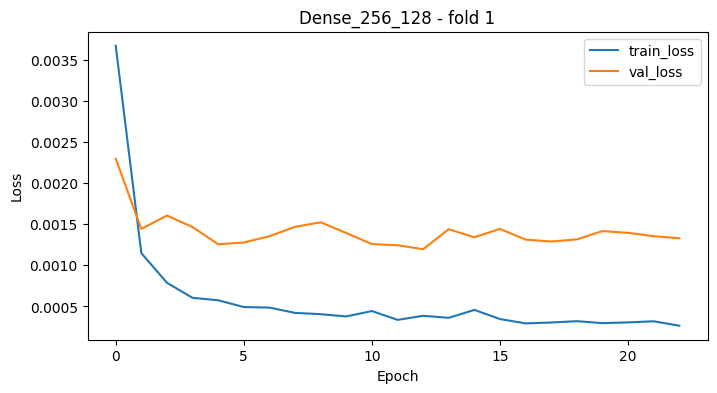

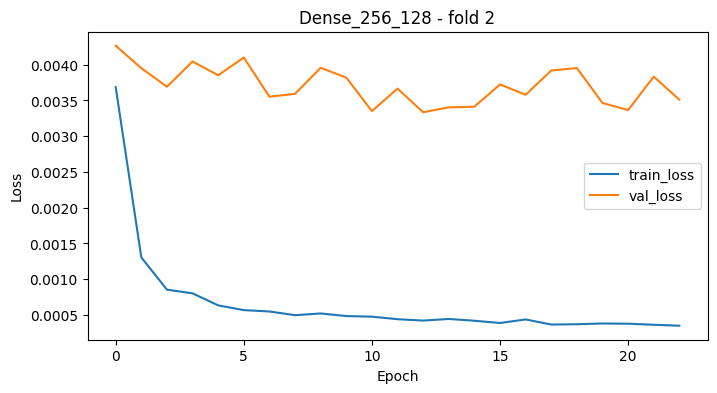

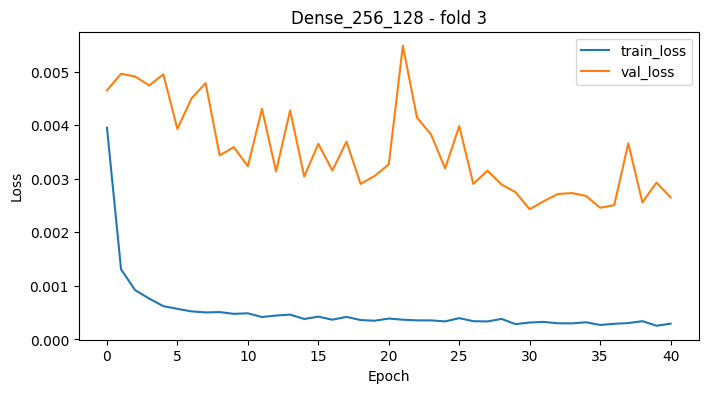

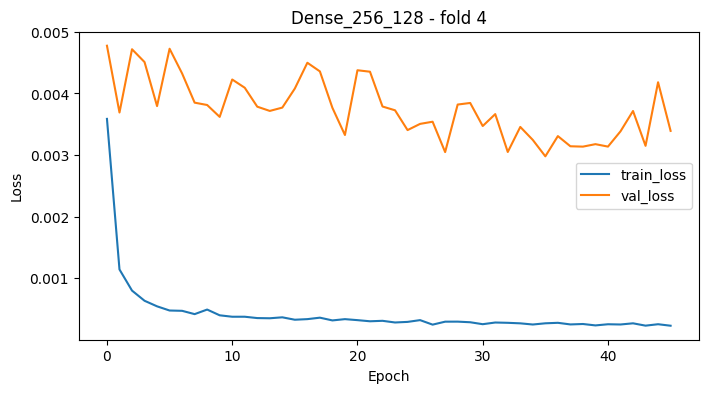

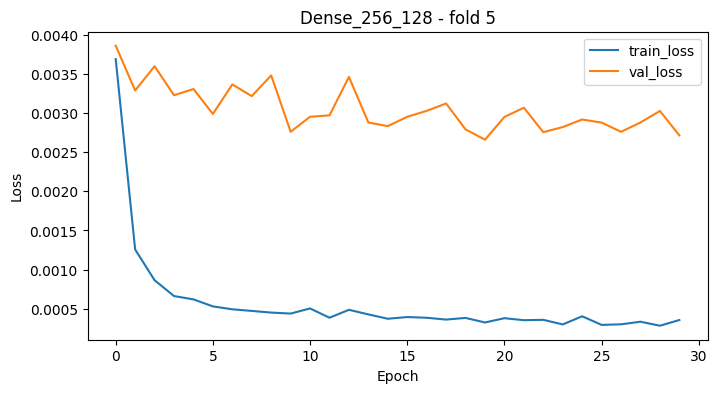

In [38]:
def plot_history(history, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="train_loss")
    plt.plot(history["val_loss"], label="val_loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

champion_histories = all_histories[champion_variant]
for fold_idx, hist in enumerate(champion_histories, start=1):
    plot_history(hist, f"{champion_variant} - fold {fold_idx}")

## Per-joint evaluation in centimeters

,joint,mean_error_cm,std_error_cm
1,left_shoulder,2.982116,0.406023
7,left_hip,3.005321,0.404623
11,left_foot,3.039876,0.250989
8,right_hip,3.040993,0.434094
3,right_shoulder,3.090529,0.436628
10,right_knee,3.185266,0.322325
9,left_knee,3.197950,0.417563
12,right_foot,3.238386,0.390396
0,head,3.529577,0.453355
2,left_elbow,4.002295,0.736866


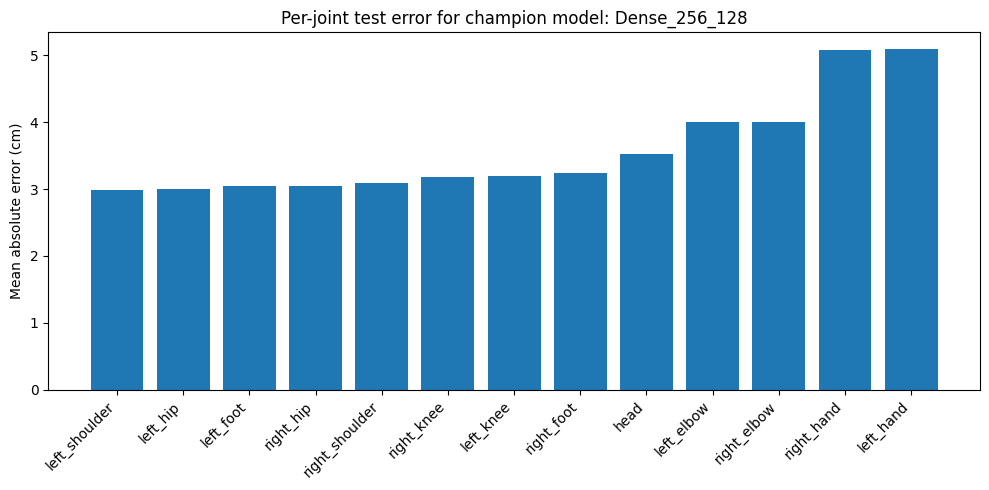

In [39]:
champion_fold_df = results_folds[results_folds["model_variant"] == champion_variant].copy()
joint_mae_matrix = np.array(champion_fold_df["joint_mae_cm"].tolist())

joint_summary = pd.DataFrame({
    "joint": JOINTS,
    "mean_error_cm": joint_mae_matrix.mean(axis=0),
    "std_error_cm": joint_mae_matrix.std(axis=0),
}).sort_values("mean_error_cm", ascending=True)

display(joint_summary)

plt.figure(figsize=(10, 5))
plt.bar(joint_summary["joint"], joint_summary["mean_error_cm"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Mean absolute error (cm)")
plt.title(f"Per-joint test error for champion model: {champion_variant}")
plt.tight_layout()
plt.show()

## Save result tables

In [40]:
fold_results_path = output_dir / "A9_dense_conv1d_pytorch_cv_folds.csv"
summary_results_path = output_dir / "A9_dense_conv1d_pytorch_cv_summary.csv"
joint_results_path = output_dir / "A9_dense_conv1d_pytorch_joint_summary.csv"

results_folds.to_csv(fold_results_path, index=False)
results_summary.to_csv(summary_results_path, index=False)
joint_summary.to_csv(joint_results_path, index=False)

print(f"Saved fold results to: {fold_results_path}")
print(f"Saved summary results to: {summary_results_path}")
print(f"Saved joint summary to: {joint_results_path}")

Saved fold results to: reporting\results\A9_dense_conv1d_pytorch_cv_folds.csv
Saved summary results to: reporting\results\A9_dense_conv1d_pytorch_cv_summary.csv
Saved joint summary to: reporting\results\A9_dense_conv1d_pytorch_joint_summary.csv


## Retrain the champion model on almost all data

In [41]:
champion_config = next(cfg for cfg in experiment_configs if cfg["model_variant"] == champion_variant)

unique_seq_ids = np.unique(seq_ids)
train_seq_ids, val_seq_ids = train_test_split(
    unique_seq_ids,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
)

train_mask = np.isin(seq_ids, train_seq_ids)
val_mask = np.isin(seq_ids, val_seq_ids)

X_train_final = X[train_mask]
y_train_final = y[train_mask]
X_val_final = X[val_mask]
y_val_final = y[val_mask]

final_scaler = fit_scaler_on_training_sequences(X_train_final)
X_train_final_scaled = transform_sequences(X_train_final, final_scaler)
X_val_final_scaled = transform_sequences(X_val_final, final_scaler)

train_dataset_final = SequenceDataset(X_train_final_scaled, y_train_final)
val_dataset_final = SequenceDataset(X_val_final_scaled, y_val_final)

train_loader_final = DataLoader(train_dataset_final, batch_size=BATCH_SIZE, shuffle=True)
val_loader_final = DataLoader(val_dataset_final, batch_size=BATCH_SIZE, shuffle=False)

final_model = build_model(champion_family, champion_config)

In [42]:
with mlflow.start_run(run_name=f"{champion_variant}_final", nested=False):
    mlflow.log_param("final_model_family", champion_family)
    mlflow.log_param("final_model_variant", champion_variant)

    final_model, final_history, final_best_val_loss, final_best_epoch = train_model(
        model=final_model,
        train_loader=train_loader_final,
        val_loader=val_loader_final,
        optimizer_name=DEFAULT_OPTIMIZER,
        lr=LEARNING_RATE,
        epochs=EPOCHS,
        patience=PATIENCE,
    )

    mlflow.log_metric("final_best_val_loss", float(final_best_val_loss))
    mlflow.log_metric("final_best_epoch", int(final_best_epoch))

    final_model_path = artifact_dir / "A9_champion_model.pt"
    final_scaler_path = artifact_dir / "A9_champion_scaler.npz"
    final_metadata_path = artifact_dir / "A9_champion_metadata.json"

    torch.save(final_model.state_dict(), final_model_path)

    np.savez(
        final_scaler_path,
        mean=final_scaler.mean_,
        scale=final_scaler.scale_,
    )

    metadata = {
        "model_family": champion_family,
        "model_variant": champion_variant,
        "sequence_length": SEQ_LEN,
        "input_features": INPUT_FEATURES,
        "target_features": TARGET_FEATURES,
        "target_unit": TARGET_UNIT,
        "mean_cv_test_mae": float(champion_row["mean_test_mae"]),
        "mean_cv_test_mae_cm": float(champion_row["mean_test_mae_cm"]),
        "std_cv_test_mae_cm": float(champion_row["std_test_mae_cm"]),
        "best_epoch_final": int(final_best_epoch),
        "config": {k: list(v) if isinstance(v, tuple) else v for k, v in champion_config.items()},
    }

    with open(final_metadata_path, "w") as f:
        json.dump(metadata, f, indent=2)

    mlflow.log_artifact(str(final_model_path))
    mlflow.log_artifact(str(final_scaler_path))
    mlflow.log_artifact(str(final_metadata_path))

print("Saved champion model to:", final_model_path)
print("Saved scaler to:", final_scaler_path)
print("Saved metadata to:", final_metadata_path)

🏃 View run Dense_256_128_final at: https://172.27.62.170:5001/#/experiments/22/runs/ecef7549873d42ee8640b675be3fb02f
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/22
Saved champion model to: reporting\artifacts\A9_champion_model.pt
Saved scaler to: reporting\artifacts\A9_champion_scaler.npz
Saved metadata to: reporting\artifacts\A9_champion_metadata.json


## Load and reuse the champion model

In [43]:
def load_saved_scaler(npz_path):
    data = np.load(npz_path)
    scaler = StandardScaler()
    scaler.mean_ = data["mean"]
    scaler.scale_ = data["scale"]
    scaler.var_ = scaler.scale_ ** 2
    scaler.n_features_in_ = len(scaler.mean_)
    return scaler

with open(final_metadata_path, "r") as f:
    loaded_meta = json.load(f)

loaded_config = loaded_meta["config"]
if "hidden_units" in loaded_config and isinstance(loaded_config["hidden_units"], list):
    loaded_config["hidden_units"] = tuple(loaded_config["hidden_units"])
if "filters" in loaded_config and isinstance(loaded_config["filters"], list):
    loaded_config["filters"] = tuple(loaded_config["filters"])

loaded_model = build_model(loaded_meta["model_family"], loaded_config)
loaded_model.load_state_dict(torch.load(final_model_path, map_location=DEVICE))
loaded_model.to(DEVICE)
loaded_model.eval()

loaded_scaler = load_saved_scaler(final_scaler_path)

print("Loaded model:", loaded_meta["model_variant"])

X_sample = X[:5]
X_sample_scaled = transform_sequences(X_sample, loaded_scaler)

sample_ds = SequenceDataset(X_sample_scaled, y[:5])
sample_loader = DataLoader(sample_ds, batch_size=5, shuffle=False)

y_true_sample, y_pred_sample = predict_model(loaded_model, sample_loader)

sample_mae = mean_absolute_error(
    y_true_sample.reshape(-1, y_true_sample.shape[-1]),
    y_pred_sample.reshape(-1, y_pred_sample.shape[-1]),
)

print("Sample MAE:", sample_mae)
print("Sample MAE (cm):", to_cm(sample_mae))

Loaded model: Dense_256_128
Sample MAE: 0.009767190553247929
Sample MAE (cm): 0.9767190553247929


## Dead ends and findings

In [44]:
best_row = results_summary.iloc[0]
worst_row = results_summary.iloc[-1]

print("Best model:")
display(best_row)

print("Worst model:")
display(worst_row)

Best model:


model_family                  Dense
model_variant         Dense_256_128
mean_test_mae              0.035757
std_test_mae               0.004543
mean_test_mae_cm           3.575703
std_test_mae_cm            0.454288
mean_best_val_loss          0.00252
mean_best_epoch                22.6
Name: 0, dtype: object

Worst model:


model_family                    Conv1D
model_variant         Conv1D_64_128_k3
mean_test_mae                 0.038138
std_test_mae                  0.005718
mean_test_mae_cm              3.813818
std_test_mae_cm                0.57178
mean_best_val_loss            0.002497
mean_best_epoch                    5.6
Name: 3, dtype: object